# WARFARIN QML · Main Benchmark k=4 — Results Audit

**Vai trò:** notebook **chỉ đọc/kiểm định/tổng hợp** kết quả E01 (matched-input, 600 mẫu, PCA k=4) và E02 (strong classical, 4.328 mẫu, không PCA). **Không huấn luyện lại, không chia lại fold, không truy cập Final Test để tính metrics.**

### Quy tắc phân tích

- **E01 primary / original baseline:** LR, SVM, MLP không weighted; QSVC C=1; VQC seed=42. Cả 5 model được đánh giá trên **cùng 600 mẫu và cùng 5 fold**.
- **E01 diagnostics:** LR-balanced, SVM-balanced, MLP-weighted, QSVC-balanced: trình bày riêng như chẩn đoán mất cân bằng lớp.
- **E01 exploratory post-baseline:** QSVC C-grid 0.1/10 (C=1 là kiểm chứng lại baseline), VQC seed=7/123 (seed=42 là đối chiếu primary). Các giá trị này được khảo sát **sau khi đã xem baseline**, không coi là preregistered; **không chọn seed tốt nhất**.
- **E02 strong classical reference:** LR/SVM/MLP dùng full Development, 10 feature sau encoding, **không PCA**, khác cỡ mẫu so với E01; không so sánh E02–E01 như thí nghiệm cô lập lợi thế thuật toán.
- **Metric chính:** Macro-F1 trung bình ± sample SD giữa **5 folds**; báo thêm Accuracy, Balanced Accuracy, Recall High, high precision tổng hợp, confusion matrix.
- **Runtime:** chỉ báo phạm vi đo, không cộng / so sánh ngầm các con số có phạm vi khác nhau. Các model Classical và VQC đo `model.fit` (không gồm preprocessing), QSVC gốc có kernel ẩn trong `.fit`, C-grid tách kernel và `SVC.fit`.
- **Final Test:** GĐ4 đang khóa; notebook chỉ dùng `final_split.csv` để **kiểm tra ID không chồng lấn**, không lấy `X_test` hoặc `y_test` để chấm điểm hay lựa chọn cấu hình.

**Lưu ý về phạm vi lâm sàng:** Feature Policy được chấp thuận cho nghiên cứu hồi cứu với *temporal evidence UNVERIFIED*. Không sử dụng để quyết định liều thuốc.

Chạy từ đầu tới cuối bằng kernel **`nt409`** trong VS Code. File đầu ra nằm trong `docs/results/`; **không ghi đè** dữ liệu cũ.

## 1. Khởi tạo, tìm project root và kiểm tra đủ artifact đầu vào

In [1]:
from pathlib import Path
from hashlib import sha256
from importlib.metadata import version
import sys
import json

import numpy as np
import pandas as pd
import yaml
from IPython.display import display
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score, recall_score

CLASSES = ("Low", "Intermediate", "High")
FOLDS = set(range(5))

def locate_root(directory):
    p = Path(directory).resolve()
    for candidate in (p, *p.parents):
        if (candidate / "data/splits/split_manifest.json").is_file() and (candidate / "docs/experiment_matrix.csv").is_file():
            return candidate
    raise FileNotFoundError("Hãy mở notebook trong thư mục project Warfarin")

ROOT = locate_root(Path.cwd())
OUT = ROOT / "docs/results"
SPLITS = ROOT / "data/splits"

SOURCES = {
    "classical_metrics": "classical_k4_reproduced_metrics.csv",
    "classical_predictions": "classical_k4_reproduced_predictions.csv",
    "classical_config": "classical_k4_reproduced_config.json",
    "qsvc_metrics": "qsvc_k4_5fold_metrics.csv",
    "qsvc_predictions": "qsvc_k4_5fold_predictions.csv",
    "qsvc_config": "qsvc_k4_5fold_config.json",
    "qsvc_balanced_metrics": "qsvc_k4_balanced_5fold_metrics.csv",
    "qsvc_balanced_predictions": "qsvc_k4_balanced_5fold_predictions.csv",
    "qsvc_balanced_config": "qsvc_k4_balanced_5fold_config.json",
    "vqc_metrics": "vqc_k4_5fold_metrics.csv",
    "vqc_predictions": "vqc_k4_5fold_predictions.csv",
    "cgrid_metrics": "qsvc_k4_cgrid_metrics.csv",
    "cgrid_predictions": "qsvc_k4_cgrid_predictions.csv",
    "cgrid_config": "qsvc_k4_cgrid_config.json",
    "robustness_metrics": "vqc_k4_seed_robustness_metrics.csv",
    "robustness_predictions": "vqc_k4_seed_robustness_predictions.csv",
    "robustness_config": "vqc_k4_seed_robustness_config.json",
    "e02_metrics": "strong_classical_e02_metrics.csv",
    "e02_predictions": "strong_classical_e02_predictions.csv",
    "e02_config": "strong_classical_e02_config.json",
}

EXPORTS = {
    "e01_primary": OUT / "main_benchmark_k4_e01_primary.csv",
    "e01_additional": OUT / "main_benchmark_k4_e01_additional.csv",
    "e02_reference": OUT / "main_benchmark_k4_e02_reference.csv",
    "confusions": OUT / "main_benchmark_k4_confusion_matrices.csv",
    "audit": OUT / "main_benchmark_k4_audit.json",
}

missing = [str(OUT / name) for name in SOURCES.values() if not (OUT / name).is_file()]
assert not missing, "Thiếu output từ thí nghiệm trước:\n" + "\n".join(missing)
assert len(set(SOURCES.values())) == len(SOURCES)
print("[PASS] All 20 prior metrics/predictions/config artifacts found")
print("[PASS] Project root:", ROOT)
print("[INFO] This notebook trains no models")

[PASS] All 20 prior metrics/predictions/config artifacts found
[PASS] Project root: D:\Warfarin-Quantum-Machine-Learning-Classification
[INFO] This notebook trains no models


## 2. Kiểm tra dữ liệu GĐ4, Feature Policy và checksum của folds đã khóa

Không fit preprocessing/PCA ở notebook này. Các fold IDs chỉ dùng để kiểm tra rằng dự đoán của mọi model trỏ đúng vào validation rows.

In [2]:
def hash_file(path):
    h = sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

manifest_path = SPLITS / "split_manifest.json"
manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
policy_path = ROOT / "configs/feature_policy.yaml"
policy = yaml.safe_load(policy_path.read_text(encoding="utf-8"))

assert manifest["status"] == "LOCKED_BEFORE_MODEL_PERFORMANCE"
assert manifest["n_splits"] == 5 and manifest["quantum_dev_pool_size"] == 600
assert policy["training_allowed"] is True
assert len(policy["approved_X_columns"]) == 10
assert manifest["approved_features"] == policy["approved_X_columns"]
for name, digest in manifest["files"].items():
    assert hash_file(SPLITS / name) == digest, f"Split checksum mismatch: {name}"

labels = pd.read_csv(ROOT / "data/interim/labels.csv")
partitions = pd.read_csv(SPLITS / "final_split.csv")
qfolds = pd.read_csv(SPLITS / "quantum_dev_folds.csv")
dfolds = pd.read_csv(SPLITS / "development_folds.csv")

assert len(labels) == len(partitions) == 5410
assert labels["raw_row_index"].is_unique
assert set(labels["target_group"]) == set(CLASSES)
assert partitions["raw_row_index"].is_unique
assert qfolds["raw_row_index"].is_unique and dfolds["raw_row_index"].is_unique
assert set(qfolds["fold_id"]) == set(dfolds["fold_id"]) == FOLDS

all_ids = set(labels["raw_row_index"].astype(int))
dev_ids = set(partitions.loc[partitions["partition"] == "development", "raw_row_index"].astype(int))
test_ids = set(partitions.loc[partitions["partition"] == "final_test", "raw_row_index"].astype(int))
qdev_ids = set(qfolds["raw_row_index"].astype(int))
assert len(dev_ids) == 4328 and len(test_ids) == 1082
assert dev_ids.isdisjoint(test_ids) and dev_ids | test_ids == all_ids
assert len(qdev_ids) == 600 and qdev_ids.issubset(dev_ids) and qdev_ids.isdisjoint(test_ids)
assert set(dfolds["raw_row_index"].astype(int)) == dev_ids

label_by_id = dict(zip(labels["raw_row_index"].astype(int), labels["target_group"].astype(str)))
EXPECTED = {
    "E01": {f: set(qfolds.loc[qfolds["fold_id"] == f, "raw_row_index"].astype(int)) for f in range(5)},
    "E02": {f: set(dfolds.loc[dfolds["fold_id"] == f, "raw_row_index"].astype(int)) for f in range(5)},
}
assert all(len(EXPECTED["E01"][f]) == 120 for f in FOLDS)
assert sorted(len(EXPECTED["E02"][f]) for f in FOLDS) == [865, 865, 866, 866, 866]
for exp, groups in EXPECTED.items():
    assert set().union(*groups.values()) == (qdev_ids if exp == "E01" else dev_ids)
    for f in FOLDS:
        assert groups[f].isdisjoint(test_ids)
        assert groups[f].isdisjoint(set().union(*(groups[j] for j in FOLDS if j != f)))
print("[PASS] Source labels and locked 5-fold split checksums")
print("[PASS] E01: 600 validation IDs; E02: 4328 validation IDs")
print("[PASS] Final Test: 1082 unique IDs, absent from both CV protocols")

[PASS] Source labels and locked 5-fold split checksums
[PASS] E01: 600 validation IDs; E02: 4328 validation IDs
[PASS] Final Test: 1082 unique IDs, absent from both CV protocols


## 3. Đọc metrics + predictions, chuẩn hóa tên cấu hình

Giữ đúng provenance: Classical reproduced, QSVC/VQC primary, weighted diagnostics, C-grid exploratory, seed robustness exploratory và E02 Strong Classical.

In [3]:
def read_pair(metrics_key, predictions_key, kind, experiment, role, runtime_scope):
    m = pd.read_csv(OUT / SOURCES[metrics_key])
    p = pd.read_csv(OUT / SOURCES[predictions_key])
    assert {"fold", "macro_f1", "accuracy", "balanced_accuracy", "recall_high"}.issubset(m.columns)
    assert {"fold", "raw_row_index", "actual", "predicted"}.issubset(p.columns)

    if kind == "model":
        assert "model" in m and "model" in p
        m["variant"] = m["model"].astype(str)
        p["variant"] = p["model"].astype(str)
    elif kind == "qsvc":
        m["variant"] = p["variant"] = "QSVC (C=1)"
    elif kind == "qsvc_balanced":
        m["variant"] = p["variant"] = "QSVC-balanced (C=1)"
    elif kind == "vqc_primary":
        m["variant"] = p["variant"] = "VQC (seed=42)"
    elif kind == "cgrid":
        assert "C" in m and "C" in p
        m["variant"] = m["C"].map(lambda x: f"QSVC (C={x:g})")
        p["variant"] = p["C"].map(lambda x: f"QSVC (C={x:g})")
    elif kind == "seeds":
        assert "seed" in m and "seed" in p
        m["variant"] = m["seed"].map(lambda x: f"VQC (seed={int(x)})")
        p["variant"] = p["seed"].map(lambda x: f"VQC (seed={int(x)})")
    else:
        raise ValueError(kind)

    m["fold"] = pd.to_numeric(m["fold"]).astype(int)
    p["fold"] = pd.to_numeric(p["fold"]).astype(int)
    p["raw_row_index"] = pd.to_numeric(p["raw_row_index"]).astype(int)
    m["experiment"] = p["experiment"] = experiment
    m["role"] = p["role"] = role
    m["runtime_scope"] = runtime_scope
    m["source_metrics"] = SOURCES[metrics_key]
    m["source_predictions"] = SOURCES[predictions_key]
    return m, p

DATASETS = {
    "classical": read_pair("classical_metrics", "classical_predictions", "model", "E01", "primary_or_imbalance_diagnostic", "estimator.fit_only_no_preprocessing"),
    "qsvc": read_pair("qsvc_metrics", "qsvc_predictions", "qsvc", "E01", "original_baseline", "QSVC.fit_includes_internal_kernel"),
    "qsvc_balanced": read_pair("qsvc_balanced_metrics", "qsvc_balanced_predictions", "qsvc_balanced", "E01", "imbalance_diagnostic", "QSVC.fit_includes_internal_kernel"),
    "vqc": read_pair("vqc_metrics", "vqc_predictions", "vqc_primary", "E01", "original_baseline", "VQC.fit_only_no_preprocessing"),
    "cgrid": read_pair("cgrid_metrics", "cgrid_predictions", "cgrid", "E01", "exploratory_post_baseline", "kernel_construction_and_SVC_fit_reported_separately"),
    "robustness": read_pair("robustness_metrics", "robustness_predictions", "seeds", "E01", "seed_robustness_post_baseline", "VQC.fit_only_no_preprocessing"),
    "e02": read_pair("e02_metrics", "e02_predictions", "model", "E02", "strong_classical_reference", "estimator.fit_only_no_preprocessing"),
}

assert set(DATASETS["classical"][0]["variant"]) == {"LR", "SVM", "MLP", "LR-balanced", "SVM-balanced", "MLP-weighted"}
assert set(DATASETS["cgrid"][0]["variant"]) == {"QSVC (C=0.1)", "QSVC (C=1)", "QSVC (C=10)"}
assert set(DATASETS["robustness"][0]["variant"]) == {"VQC (seed=7)", "VQC (seed=42)", "VQC (seed=123)"}
assert set(DATASETS["e02"][0]["variant"]) == {"LR", "SVM", "MLP"}

print("[PASS] Read 7 model/result groups; E01 and E02 remain separate")
for name, (m, p) in DATASETS.items():
    print(f"  {name:15s}: {len(m):2d} fold-metrics, {len(p):5d} predictions")

[PASS] Read 7 model/result groups; E01 and E02 remain separate
  classical      : 30 fold-metrics,  3600 predictions
  qsvc           :  5 fold-metrics,   600 predictions
  qsvc_balanced  :  5 fold-metrics,   600 predictions
  vqc            :  5 fold-metrics,   600 predictions
  cgrid          : 15 fold-metrics,  1800 predictions
  robustness     : 15 fold-metrics,  1800 predictions
  e02            : 15 fold-metrics, 12984 predictions


## 4. Audit chéo **từng fold** bằng dự đoán gốc

Đối chiếu số dòng, `fold_id`, `raw_row_index`, nhãn thực tế và **tái tính** Macro-F1/Accuracy/Balanced Accuracy/Recall High. Phát hiện sai lệch thì dừng trước khi xuất file.

In [4]:
def audit_dataset(name, metrics, predictions):
    exp = str(metrics["experiment"].iloc[0])
    assert exp in EXPECTED and set(predictions["experiment"]) == {exp}
    assert not metrics.duplicated(["variant", "fold"]).any()
    assert not predictions.duplicated(["variant", "fold", "raw_row_index"]).any()
    assert set(metrics["variant"]) == set(predictions["variant"])
    assert all(metrics["fold"].isin(FOLDS)) and all(predictions["fold"].isin(FOLDS))
    assert (predictions["actual"].isin(CLASSES) & predictions["predicted"].isin(CLASSES)).all()

    all_rows = []
    for variant in sorted(metrics["variant"].unique()):
        gm = metrics.loc[metrics["variant"] == variant]
        gp = predictions.loc[predictions["variant"] == variant]
        assert len(gm) == 5 and set(gm["fold"]) == FOLDS
        assert gp["raw_row_index"].is_unique
        assert set(gp["raw_row_index"]) == (qdev_ids if exp == "E01" else dev_ids)
        assert set(gp["raw_row_index"]).isdisjoint(test_ids)

        for fold_id in range(5):
            row = gm.loc[gm["fold"] == fold_id]
            subset = gp.loc[gp["fold"] == fold_id]
            assert len(row) == 1
            assert set(subset["raw_row_index"]) == EXPECTED[exp][fold_id]
            assert (subset["actual"] == subset["raw_row_index"].map(label_by_id)).all()
            actual, predicted = subset["actual"].to_numpy(), subset["predicted"].to_numpy()
            checks = {
                "macro_f1": f1_score(actual, predicted, labels=CLASSES, average="macro", zero_division=0),
                "accuracy": accuracy_score(actual, predicted),
                "balanced_accuracy": balanced_accuracy_score(actual, predicted),
                "recall_high": recall_score(actual, predicted, labels=CLASSES, average=None, zero_division=0)[2],
            }
            m = row.iloc[0]
            for metric, calculated in checks.items():
                assert np.isclose(float(m[metric]), float(calculated), atol=1e-10, rtol=1e-8), (name, variant, fold_id, metric, m[metric], calculated)
            if "train_n" in gm.columns:
                assert int(m["train_n"]) == (480 if exp == "E01" else 4328 - len(subset))
            if "val_n" in gm.columns:
                assert int(m["val_n"]) == len(subset)
            if "k" in gm.columns:
                assert int(m["k"]) == 4
            if "pca_k" in gm.columns:
                assert int(m["pca_k"]) == 4
            all_rows.append((variant, fold_id, int(len(subset))))
    return all_rows

AUDIT_ROWS = {}
for name, (m, p) in DATASETS.items():
    rows = audit_dataset(name, m, p)
    AUDIT_ROWS[name] = rows
    print(f"[PASS] {name:<15}: {len(rows)} model-fold groups, full prediction/ID/metric match")

# Original QSVC C=1 must be identical to the precomputed-kernel C-grid C=1.
old = DATASETS["qsvc"][1].sort_values(["fold", "raw_row_index"])
new = DATASETS["cgrid"][1]
new = new.loc[new["variant"] == "QSVC (C=1)"].sort_values(["fold", "raw_row_index"])
assert len(old) == len(new) == 600
assert old[["fold", "raw_row_index", "actual", "predicted"]].reset_index(drop=True).equals(
    new[["fold", "raw_row_index", "actual", "predicted"]].reset_index(drop=True))

# Seed=42 in robustness must reproduce the primary VQC predictions; we do not count it twice.
vold = DATASETS["vqc"][1].sort_values(["fold", "raw_row_index"])
vnew = DATASETS["robustness"][1]
vnew = vnew.loc[vnew["variant"] == "VQC (seed=42)"].sort_values(["fold", "raw_row_index"])
assert len(vold) == len(vnew) == 600
assert vold[["fold", "raw_row_index", "actual", "predicted"]].reset_index(drop=True).equals(
    vnew[["fold", "raw_row_index", "actual", "predicted"]].reset_index(drop=True))

print("[PASS] C-grid C=1 reproduces all 600 original QSVC predictions")
print("[PASS] Robustness seed=42 reproduces all 600 primary VQC predictions")
print("[PASS] All source metrics recomputed from locked validation predictions")

[PASS] classical      : 30 model-fold groups, full prediction/ID/metric match
[PASS] qsvc           : 5 model-fold groups, full prediction/ID/metric match
[PASS] qsvc_balanced  : 5 model-fold groups, full prediction/ID/metric match
[PASS] vqc            : 5 model-fold groups, full prediction/ID/metric match
[PASS] cgrid          : 15 model-fold groups, full prediction/ID/metric match
[PASS] robustness     : 15 model-fold groups, full prediction/ID/metric match
[PASS] e02            : 15 model-fold groups, full prediction/ID/metric match
[PASS] C-grid C=1 reproduces all 600 original QSVC predictions
[PASS] Robustness seed=42 reproduces all 600 primary VQC predictions
[PASS] All source metrics recomputed from locked validation predictions


## 5. Cấu hình và provenance: phân biệt primary, diagnostic và exploratory

Dữ liệu từ `docs/results/*_config.json` được kiểm tra để phát hiện mô hình không đúng protocol. Những phần bổ sung sau baseline **không được đổi nhãn thành predeclared**.

In [5]:
configs = {key: json.loads((OUT / SOURCES[key]).read_text(encoding="utf-8"))
           for key in ("classical_config", "qsvc_config", "qsvc_balanced_config", "cgrid_config", "robustness_config", "e02_config")}
assert configs["classical_config"]["pca_k"] == 4
assert configs["cgrid_config"]["pca_k"] == 4
assert configs["robustness_config"]["pca_k"] == 4
assert configs["e02_config"]["experiment_id"] == "E02"
assert configs["e02_config"]["pca"] is None
assert configs["e02_config"]["training_pool"] == "full_development_4328"
assert configs["e02_config"]["class_weight"] is None
assert configs["e02_config"]["final_test_used_for_model_fit_or_evaluation"] is False
assert "EXPLORATORY" in configs["cgrid_config"]["status"]
assert "EXPLORATORY" in configs["robustness_config"]["status"]

matrix = pd.read_csv(ROOT / "docs/experiment_matrix.csv")
assert {"E01", "E02"}.issubset(set(matrix["experiment_id"]))
assert matrix.loc[matrix["experiment_id"] == "E01", "training_pool"].iloc[0] == "quantum_dev_pool"
assert matrix.loc[matrix["experiment_id"] == "E02", "training_pool"].iloc[0] == "full_development"

print("[PASS] E01 matched PCA k=4 and E02 full-encoded/no PCA configuration")
print("[PASS] C-grid and robustness are marked EXPLORATORY_POST_BASELINE")
print("[INFO] No final model chosen or frozen in this notebook")

[PASS] E01 matched PCA k=4 and E02 full-encoded/no PCA configuration
[PASS] C-grid and robustness are marked EXPLORATORY_POST_BASELINE
[INFO] No final model chosen or frozen in this notebook


## 6. Tính bảng tổng hợp theo fold và High-class error analysis

Lưu cả `Recall High mean` (trung bình recall qua 5 folds) và `High recall pooled` (tổng true positive / tổng số High). Hai con số có thể khác nhau vì số mẫu High từng fold không đều. Không được nhầm High precision với High recall.

In [6]:
def summarize(metrics, predictions, variant, source_name, classification):
    gm = metrics.loc[metrics["variant"] == variant].sort_values("fold")
    gp = predictions.loc[predictions["variant"] == variant]
    assert len(gm) == 5
    y_true, y_pred = gp["actual"].to_numpy(), gp["predicted"].to_numpy()
    cm = confusion_matrix(y_true, y_pred, labels=CLASSES)
    high_tp, high_actual, high_predicted = int(cm[2,2]), int(cm[2,:].sum()), int(cm[:,2].sum())
    exp = str(gm["experiment"].iloc[0])
    result = {
        "experiment": exp,
        "model": variant,
        "classification": classification,
        "data_pool": "quantum_dev_pool_600" if exp == "E01" else "development_4328",
        "representation": "PCA_k4" if exp == "E01" else "Full_encoded_no_PCA",
        "folds": 5,
        "validation_predictions": len(gp),
        "macro_f1_mean": float(gm["macro_f1"].mean()),
        "macro_f1_sd": float(gm["macro_f1"].std(ddof=1)),
        "accuracy_mean": float(gm["accuracy"].mean()),
        "accuracy_sd": float(gm["accuracy"].std(ddof=1)),
        "balanced_accuracy_mean": float(gm["balanced_accuracy"].mean()),
        "recall_high_mean": float(gm["recall_high"].mean()),
        "high_true_positive": high_tp,
        "high_actual": high_actual,
        "high_predicted": high_predicted,
        "precision_high_pooled": high_tp / high_predicted if high_predicted else 0.,
        "recall_high_pooled": high_tp / high_actual if high_actual else 0.,
        "runtime_scope": str(gm["runtime_scope"].iloc[0]),
        "fit_seconds_mean": float(gm["fit_seconds"].mean()) if "fit_seconds" in gm else np.nan,
        "predict_seconds_mean": float(gm["predict_seconds"].mean()) if "predict_seconds" in gm else np.nan,
        "kernel_train_seconds_mean": float(gm["kernel_train_seconds"].mean()) if "kernel_train_seconds" in gm else np.nan,
        "kernel_val_seconds_mean": float(gm["kernel_val_seconds"].mean()) if "kernel_val_seconds" in gm else np.nan,
        "svc_fit_seconds_mean": float(gm["svc_fit_seconds"].mean()) if "svc_fit_seconds" in gm else np.nan,
        "svc_predict_seconds_mean": float(gm["svc_predict_seconds"].mean()) if "svc_predict_seconds" in gm else np.nan,
        "source_metrics": gm["source_metrics"].iloc[0],
        "source_predictions": gm["source_predictions"].iloc[0],
    }
    cm_rows = [dict(experiment=exp, model=variant, classification=classification,
                    actual=CLASSES[i], predicted=CLASSES[j], count=int(cm[i,j]))
               for i in range(3) for j in range(3)]
    return result, cm_rows

PRIMARY = [
    ("classical", "LR"), ("classical", "SVM"), ("classical", "MLP"),
    ("qsvc", "QSVC (C=1)"), ("vqc", "VQC (seed=42)"),
]
ADDITIONAL = [
    ("classical", "LR-balanced", "imbalance_diagnostic"),
    ("classical", "SVM-balanced", "imbalance_diagnostic"),
    ("classical", "MLP-weighted", "imbalance_diagnostic"),
    ("qsvc_balanced", "QSVC-balanced (C=1)", "imbalance_diagnostic"),
    ("cgrid", "QSVC (C=0.1)", "EXPLORATORY_POST_BASELINE"),
    ("cgrid", "QSVC (C=10)", "EXPLORATORY_POST_BASELINE"),
    ("robustness", "VQC (seed=7)", "EXPLORATORY_POST_BASELINE"),
    ("robustness", "VQC (seed=123)", "EXPLORATORY_POST_BASELINE"),
]
E02_MODELS = [("e02", name) for name in ("LR", "SVM", "MLP")]

cm_all = []
def make_table(specs, default_role=None):
    result = []
    for spec in specs:
        key, variant = spec[0], spec[1]
        role = spec[2] if len(spec) == 3 else default_role
        row, matrices = summarize(*DATASETS[key], variant, key, role)
        result.append(row)
        cm_all.extend(matrices)
    return pd.DataFrame(result).sort_values("macro_f1_mean", ascending=False).reset_index(drop=True)

primary_table = make_table(PRIMARY, "primary_original_cv")
additional_table = make_table(ADDITIONAL)
e02_table = make_table(E02_MODELS, "strong_classical_reference")
confusion_table = pd.DataFrame(cm_all)
assert len(primary_table) == 5 and len(additional_table) == 8 and len(e02_table) == 3
assert len(confusion_table) == (5 + 8 + 3) * 9
assert primary_table["validation_predictions"].eq(600).all()
assert additional_table["validation_predictions"].eq(600).all()
assert e02_table["validation_predictions"].eq(4328).all()

print("[PASS] Aggregated 5 primary E01 / 8 E01 diagnostics & exploratory / 3 E02 models")

[PASS] Aggregated 5 primary E01 / 8 E01 diagnostics & exploratory / 3 E02 models


## 7. E01 — Primary matched-input benchmark (bảng chính)

**Nên dùng bảng này cho câu hỏi RQ1 về Classical vs Quantum ở cùng input và cùng data budget.** Không trộn thêm QSVC C=10 hoặc seed VQC bổ sung vào bảng primary.

In [7]:
cols = ["model", "macro_f1_mean", "macro_f1_sd", "accuracy_mean", "balanced_accuracy_mean", "recall_high_mean", "precision_high_pooled"]
print("=== E01 PRIMARY | N=600 | PCA k=4 | Same locked 5 folds ===")
display(primary_table[cols].round(5))
assert primary_table["model"].nunique() == 5

=== E01 PRIMARY | N=600 | PCA k=4 | Same locked 5 folds ===


,model,macro_f1_mean,macro_f1_sd,accuracy_mean,balanced_accuracy_mean,recall_high_mean,precision_high_pooled
0,SVM,0.40136,0.02281,0.61333,0.42655,0.000,0.00000
1,LR,0.38413,0.01781,0.58667,0.41021,0.000,0.00000
2,QSVC (C=1),0.36026,0.01668,0.56333,0.38795,0.000,0.00000
3,VQC (seed=42),0.34305,0.03350,0.38333,0.37129,0.325,0.14535
4,MLP,0.34231,0.06018,0.58000,0.38468,0.000,0.00000


## 8. E01 — Class imbalance diagnostics và post-baseline sensitivity

Trong bảng này, **C=0.1/10** và **seed 7/123** là exploratory, không so sánh như cấu hình đã được khóa trước E01. QSVC C=1 từ C-grid và seed VQC 42 từ robustness đã được audit tương đương primary và **không được tính như thí nghiệm mới độc lập**.

In [8]:
cols2 = ["model", "classification", "macro_f1_mean", "macro_f1_sd", "accuracy_mean", "recall_high_mean", "precision_high_pooled"]
print("=== E01 ADDITIONAL / DIAGNOSTIC / EXPLORATORY ===")
display(additional_table[cols2].round(5))
print("[INFO] Do not retroactively select C=10 or best seed and report its CV score as unbiased model performance")

=== E01 ADDITIONAL / DIAGNOSTIC / EXPLORATORY ===


,model,classification,macro_f1_mean,macro_f1_sd,accuracy_mean,recall_high_mean,precision_high_pooled
0,QSVC (C=10),EXPLORATORY_POST_BASELINE,0.42239,0.04635,0.50833,0.22417,0.22078
1,SVM-balanced,imbalance_diagnostic,0.41867,0.03282,0.44000,0.47500,0.17822
2,LR-balanced,imbalance_diagnostic,0.39175,0.04356,0.41167,0.48917,0.18974
3,QSVC-balanced (C=1),imbalance_diagnostic,0.38386,0.04861,0.41667,0.38333,0.16111
4,MLP-weighted,imbalance_diagnostic,0.35161,0.09506,0.41167,0.22500,0.11972
5,VQC (seed=7),EXPLORATORY_POST_BASELINE,0.31465,0.03592,0.34333,0.32833,0.12626
6,VQC (seed=123),EXPLORATORY_POST_BASELINE,0.29712,0.02364,0.34167,0.28667,0.11892
7,QSVC (C=0.1),EXPLORATORY_POST_BASELINE,0.23470,0.00104,0.54333,0.00000,0.00000


[INFO] Do not retroactively select C=10 or best seed and report its CV score as unbiased model performance


## 9. E02 — Strong Classical Reference, trình bày riêng

Dùng 4.328 mẫu Development, 10 feature sau encoding và **không PCA**. Kết quả E02 là tham chiếu bối cảnh với nhiều dữ liệu hơn, **không phải** so sánh apples-to-apples với E01.

In [9]:
print("=== E02 STRONG CLASSICAL | N=4328 | Full encoded features | Same E02 5 folds ===")
display(e02_table[["model", "macro_f1_mean", "macro_f1_sd", "accuracy_mean", "balanced_accuracy_mean", "recall_high_mean", "precision_high_pooled"]].round(5))

=== E02 STRONG CLASSICAL | N=4328 | Full encoded features | Same E02 5 folds ===


,model,macro_f1_mean,macro_f1_sd,accuracy_mean,balanced_accuracy_mean,recall_high_mean,precision_high_pooled
0,LR,0.58594,0.00772,0.68184,0.56296,0.25636,0.57551
1,MLP,0.54045,0.03929,0.66751,0.52983,0.15818,0.59184
2,SVM,0.53037,0.01649,0.66844,0.51904,0.12909,0.59664


## 10. Confusion matrices & biểu đồ

Confusion matrix gồm hàng là nhãn **thực**, cột là nhãn **dự đoán**; tổng hợp OOF (out-of-fold) trên đúng một lần validation cho mỗi ID/model. Biểu đồ E01 và E02 được vẽ **riêng**.

E01 — QSVC (C=1): Actual (rows) × Predicted (columns)


predicted,Low,Intermediate,High
actual,,,
Low,64,134,0
Intermediate,51,274,1
High,12,64,0


E01 — VQC (seed=42): Actual (rows) × Predicted (columns)


predicted,Low,Intermediate,High
actual,,,
Low,81,67,50
Intermediate,105,124,97
High,25,26,25


E02 — LR: Actual (rows) × Predicted (columns)


predicted,Low,Intermediate,High
actual,,,
Low,862,557,10
Intermediate,307,1948,94
High,8,401,141


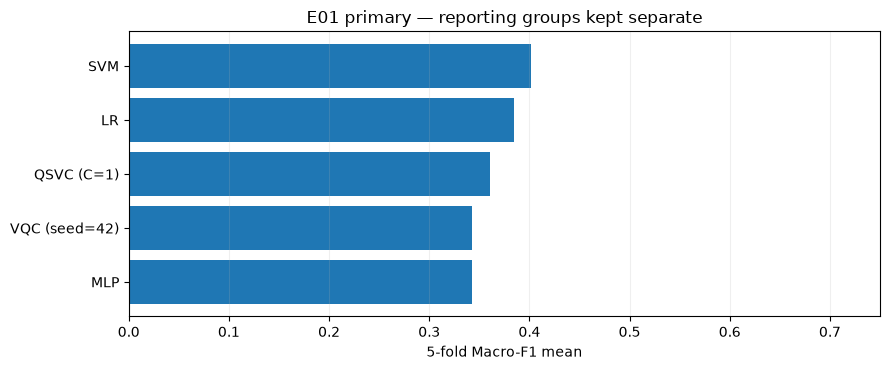

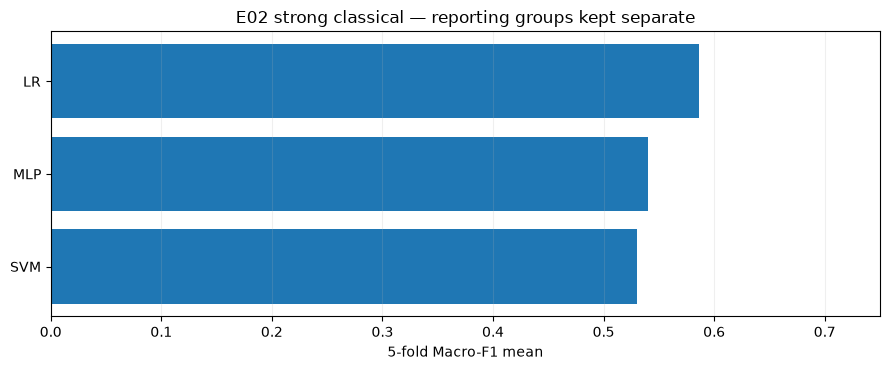

In [10]:
def show_confusion(experiment, model):
    df = confusion_table.loc[(confusion_table["experiment"] == experiment) & (confusion_table["model"] == model)]
    matrix = (df.pivot(index="actual", columns="predicted", values="count")
                .reindex(index=CLASSES, columns=CLASSES))
    assert matrix.notna().all().all()
    assert matrix.to_numpy().sum() == (600 if experiment == "E01" else 4328)
    print(f"{experiment} — {model}: Actual (rows) × Predicted (columns)")
    display(matrix.astype(int))

show_confusion("E01", "QSVC (C=1)")
show_confusion("E01", "VQC (seed=42)")
show_confusion("E02", "LR")

for name, table in (("E01 primary", primary_table), ("E02 strong classical", e02_table)):
    fig, ax = plt.subplots(figsize=(9, 3.8))
    values = table.sort_values("macro_f1_mean")
    ax.barh(values["model"], values["macro_f1_mean"])
    ax.set_xlim(0, 0.75)
    ax.set_xlabel("5-fold Macro-F1 mean")
    ax.set_title(name + " — reporting groups kept separate")
    ax.grid(axis="x", alpha=.2)
    plt.tight_layout()
    plt.show()

## 11. Runtime — không gộp các phạm vi đo khác nhau

- **Classical E01/E02:** `fit_seconds` là thời gian fit estimator, không tính preprocessing, encoding hay PCA.
- **QSVC C=1 và balanced:** `fit_seconds` là thời gian fit QSVC, chứa thực thi kernel theo cách QSVC nội bộ gọi.
- **QSVC C-grid:** `kernel_train_seconds`, `kernel_val_seconds`, `svc_fit_seconds`, `svc_predict_seconds` đo riêng; dựng kernel **chia sẻ cho các C**, không cộng cho từng C như ba lần tính kernel độc lập.
- **VQC:** `fit_seconds` chạy 60 objective evaluations, sampler 1024 shots; runtime tùy tải máy và sampling.

Thống kê mang tính mô tả trên môi trường hiện tại, không chứng minh ưu thế tốc độ giữa họ thuật toán.

In [11]:
runtime_cols = ["model", "runtime_scope", "fit_seconds_mean", "predict_seconds_mean",
                "kernel_train_seconds_mean", "kernel_val_seconds_mean", "svc_fit_seconds_mean", "svc_predict_seconds_mean"]
print("=== E01 PRIMARY RUNTIME (measurement scopes shown) ===")
display(primary_table[runtime_cols].round(3))
print("=== E01 EXPLORATORY C-GRID RUNTIME (kernel reused within fold) ===")
display(additional_table.loc[additional_table["model"].str.contains("QSVC (C=", regex=False), runtime_cols].round(3))
print("=== E02 RUNTIME (estimator fit only) ===")
display(e02_table[runtime_cols].round(3))

=== E01 PRIMARY RUNTIME (measurement scopes shown) ===


,model,runtime_scope,fit_seconds_mean,predict_seconds_mean,kernel_train_seconds_mean,kernel_val_seconds_mean,svc_fit_seconds_mean,svc_predict_seconds_mean
0,SVM,estimator.fit_only_no_preprocessing,0.007,0.002,NaN,NaN,NaN,NaN
1,LR,estimator.fit_only_no_preprocessing,0.010,0.000,NaN,NaN,NaN,NaN
2,QSVC (C=1),QSVC.fit_includes_internal_kernel,1.146,0.620,NaN,NaN,NaN,NaN
3,VQC (seed=42),VQC.fit_only_no_preprocessing,161.401,0.816,NaN,NaN,NaN,NaN
4,MLP,estimator.fit_only_no_preprocessing,0.075,0.000,NaN,NaN,NaN,NaN


=== E01 EXPLORATORY C-GRID RUNTIME (kernel reused within fold) ===


,model,runtime_scope,fit_seconds_mean,predict_seconds_mean,kernel_train_seconds_mean,kernel_val_seconds_mean,svc_fit_seconds_mean,svc_predict_seconds_mean
0,QSVC (C=10),kernel_construction_and_SVC_fit_reported_separ...,NaN,NaN,1.329,0.335,0.009,0.001
7,QSVC (C=0.1),kernel_construction_and_SVC_fit_reported_separ...,NaN,NaN,1.329,0.335,0.003,0.000


=== E02 RUNTIME (estimator fit only) ===


,model,runtime_scope,fit_seconds_mean,predict_seconds_mean,kernel_train_seconds_mean,kernel_val_seconds_mean,svc_fit_seconds_mean,svc_predict_seconds_mean
0,LR,estimator.fit_only_no_preprocessing,0.021,0.000,NaN,NaN,NaN,NaN
1,MLP,estimator.fit_only_no_preprocessing,0.282,0.001,NaN,NaN,NaN,NaN
2,SVM,estimator.fit_only_no_preprocessing,0.260,0.128,NaN,NaN,NaN,NaN


## 12. Xuất bảng và audit manifest (không ghi đè)

Xuất 4 CSV + 1 JSON, giữ nguyên toàn bộ nguồn dữ liệu. Audit manifest ghi SHA-256 của file đầu vào, phiên bản thư viện, điều kiện CV, trạng thái lựa chọn cấu hình. Việc **chốt model/final-test evaluation là bước riêng**, không được làm tự động khi chạy notebook tổng hợp này.

In [12]:
# Last check before writing any user-visible result artifacts.
collisions = [str(path) for path in EXPORTS.values() if path.exists()]
if collisions:
    raise FileExistsError("Refuse overwrite existing benchmark artifacts: " + "; ".join(collisions))

sources_sha256 = {name: hash_file(OUT / filename) for name, filename in SOURCES.items()}
status = {
    "stage": "MAIN_BENCHMARK_K4_RESULTS_AUDIT",
    "status": "DEVELOPMENT_CV_SUMMARIZED_CONFIG_SELECTION_NOT_FROZEN",
    "experiment_groups": {
        "E01_primary": "same 600 IDs, 5 locked folds, PCA k=4, 5 unweighted / original-baseline model families",
        "E01_additional": "4 imbalance diagnostics + 2 post-baseline C values + 2 post-baseline VQC seeds",
        "E02_reference": "same 4328 development IDs, 5 separate locked folds, 10 features after encoding, no PCA",
    },
    "primary_models": primary_table["model"].tolist(),
    "additional_variants": additional_table[["model", "classification"]].to_dict(orient="records"),
    "e02_models": e02_table["model"].tolist(),
    "fold_count": 5,
    "final_test_size": 1082,
    "final_test_used_for_model_fit_or_evaluation": False,
    "final_test_used_only_to_check_disjointness": True,
    "C1_prediction_agreement_with_baseline": "600/600",
    "VQC_seed42_prediction_agreement_with_primary": "600/600",
    "post_baseline_exploration": ["QSVC C=0.1 and C=10", "VQC seeds 7 and 123"],
    "no_claim_of_unbiased_tuned_cv_estimate": True,
    "no_automatic_final_model_selection": True,
    "retrospective_feature_temporal_evidence": "UNVERIFIED",
    "metric_definition": "unweighted mean and sample SD of 5 fold metrics; pooled High precision/recall from OOF predictions",
    "runtime_note": "See runtime_scope; estimator.fit, QSVC.fit, precomputed kernel construction, and SVC.fit are not interchangeable timings",
    "files_sha256": {
        "source_results": sources_sha256,
        "split_manifest": hash_file(manifest_path),
        "feature_policy": hash_file(policy_path),
        "experiment_matrix": hash_file(ROOT / "docs/experiment_matrix.csv"),
    },
    "environment": {"python": sys.version.split()[0],
                    "versions": {pkg: version(pkg) for pkg in ("numpy", "pandas", "scikit-learn", "PyYAML")}},
}

# Exclusive creation, no overwrite. Prior preflight prevents collisions.
EXPORTS["e01_primary"].parent.mkdir(parents=True, exist_ok=True)
for key, frame in (
    ("e01_primary", primary_table),
    ("e01_additional", additional_table),
    ("e02_reference", e02_table),
    ("confusions", confusion_table),
):
    with EXPORTS[key].open("x", encoding="utf-8", newline="") as stream:
        frame.to_csv(stream, index=False)

with EXPORTS["audit"].open("x", encoding="utf-8") as stream:
    json.dump(status, stream, ensure_ascii=False, indent=2, allow_nan=False)

print("[PASS] Main benchmark k=4: 5 output artifacts saved in docs/results/")
for key, path in EXPORTS.items():
    print(" -", key, "=>", path.name)
print("[INFO] Development-only results; Final Test remains locked; final config NOT frozen")

[PASS] Main benchmark k=4: 5 output artifacts saved in docs/results/
 - e01_primary => main_benchmark_k4_e01_primary.csv
 - e01_additional => main_benchmark_k4_e01_additional.csv
 - e02_reference => main_benchmark_k4_e02_reference.csv
 - confusions => main_benchmark_k4_confusion_matrices.csv
 - audit => main_benchmark_k4_audit.json
[INFO] Development-only results; Final Test remains locked; final config NOT frozen


## 13. Checkpoint nghiệm thu Main Benchmark k=4 (chưa bàn giao)

Chỉ đánh dấu hoàn thành phần **results audit / main benchmark development CV** nếu tất cả PASS và 5 file tổng hợp đã lưu. Bước tiếp theo **phải được thảo luận với nhóm**: xác nhận cấu hình primary, quy tắc chọn C/seed và phạm vi final evaluation theo protocol. Việc chọn C=10 vì có Macro-F1 cao nhất trên chính CV đang báo cáo có bias chọn mô hình. Không thay đổi Final Test hoặc re-split để cải thiện score.

**Chưa làm trong notebook này:** retrain frozen final models, locked Final Test, paired bootstrap, learning curve, k=2 ablation, báo cáo/demo/handover. E02 mạnh hơn E01 về điểm số không thể quy cho thuật toán vì khác mẫu và representation. Đây là kết quả nghiên cứu hồi cứu, không phải công cụ kê đơn Warfarin.

**File nên giữ:** notebook cùng các CSV/JSON gốc (đủ provenance), và `main_benchmark_k4_*` mới. Không tạo thêm `scripts/` trong checkpoint này.